#  Exploratory Data Analysis (EDA)

## Import Dataset

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Folder path to the dataset on desktop
folder_path = r'C:\Users\user\CSE-CIC-IDS2018-Full'

# 10 csv files in the dataset folder 
selected_files = [
    'Friday-02-03-2018_TrafficForML_CICFlowMeter.csv',
    'Friday-16-02-2018_TrafficForML_CICFlowMeter.csv',
    'Friday-23-02-2018_TrafficForML_CICFlowMeter.csv',
    'Thursday-01-03-2018_TrafficForML_CICFlowMeter.csv',
    'Thursday-15-02-2018_TrafficForML_CICFlowMeter.csv',
    'Thursday-22-02-2018_TrafficForML_CICFlowMeter.csv',
    'Thuesday-20-02-2018_TrafficForML_CICFlowMeter.csv',
    'Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv',
    'Wednesday-21-02-2018_TrafficForML_CICFlowMeter.csv',
    'Wednesday-28-02-2018_TrafficForML_CICFlowMeter.csv'
]


## Check Columns Consistency in the 10 CSV Files 

In [2]:
ref_cols = None
mismatches = {}

for fname in selected_files:
    path = os.path.join(folder_path, fname)
    try:
        df = pd.read_csv(path, nrows=100)
        df = df[df['Label'] != 'Label']
        df.columns = df.columns.str.strip()
        
        if ref_cols is None:
            ref_cols = list(df.columns)
            print(f"Reference file: {fname}")
            print(f"Columns: {ref_cols}\n")
        elif set(df.columns) != set(ref_cols):
            extra = list(set(df.columns) - set(ref_cols))
            missing = list(set(ref_cols) - set(df.columns))
            mismatches[fname] = {'extra': extra, 'missing': missing}
    except Exception as e:
        mismatches[fname] = {'error': str(e)}

# Print mismatches
if mismatches:
    print("Files with column mismatches:")
    for fname, details in mismatches.items():
        if 'error' in details:
            print(f"{fname}: Error - {details['error'][:100]}")
        else:
            print(f"{fname}:")
            if details['extra']: print(f"  Extra columns: {details['extra']}")
            if details['missing']: print(f"  Missing columns: {details['missing']}")

Reference file: Friday-02-03-2018_TrafficForML_CICFlowMeter.csv
Columns: ['Dst Port', 'Protocol', 'Timestamp', 'Flow Duration', 'Tot Fwd Pkts', 'Tot Bwd Pkts', 'TotLen Fwd Pkts', 'TotLen Bwd Pkts', 'Fwd Pkt Len Max', 'Fwd Pkt Len Min', 'Fwd Pkt Len Mean', 'Fwd Pkt Len Std', 'Bwd Pkt Len Max', 'Bwd Pkt Len Min', 'Bwd Pkt Len Mean', 'Bwd Pkt Len Std', 'Flow Byts/s', 'Flow Pkts/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Tot', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Tot', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Len', 'Bwd Header Len', 'Fwd Pkts/s', 'Bwd Pkts/s', 'Pkt Len Min', 'Pkt Len Max', 'Pkt Len Mean', 'Pkt Len Std', 'Pkt Len Var', 'FIN Flag Cnt', 'SYN Flag Cnt', 'RST Flag Cnt', 'PSH Flag Cnt', 'ACK Flag Cnt', 'URG Flag Cnt', 'CWE Flag Count', 'ECE Flag Cnt', 'Down/Up Ratio', 'Pkt Size Avg', 'Fwd Seg Size Avg', 'Bwd Seg S

## Remove Extra Columns 

In [3]:
cleaned_dfs = {}
cols_to_remove =  ['Dst IP', 'Src Port', 'Src IP', 'Flow ID']

for fname in selected_files:
    path = os.path.join(folder_path, fname)
    try:
        df = pd.read_csv(path)
        df.columns = df.columns.str.strip()
        df = df[df['Label'] != 'Label']
        
        # Remove extra columns in the Thuesday file
        if fname == 'Thuesday-20-02-2018_TrafficForML_CICFlowMeter.csv':
            remove = [col for col in cols_to_remove if col in df.columns]
            if remove: 
                df = df.drop(columns=remove)
                print(f"Removed columns from Thuesday: {remove}")
        
        cleaned_dfs[fname] = df
        
    except Exception as e:
        print(f"Error processing {fname}: {str(e)[:100]}")

C:\Users\user\AppData\Local\Temp\ipykernel_9972\123533496.py:7: DtypeWarning: Columns (0,1,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path)
C:\Users\user\AppData\Local\Temp\ipykernel_9972\123533496.py:7: DtypeWarning: Columns (0,1,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path)


Removed columns from Thuesday: ['Dst IP', 'Src Port', 'Src IP', 'Flow ID']


C:\Users\user\AppData\Local\Temp\ipykernel_9972\123533496.py:7: DtypeWarning: Columns (0,1,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path)


## Check Class Distribution


Friday-02-03-2018_TrafficForML_CICFlowMeter.csv
Label
Benign    762384
Bot       286191
Name: count, dtype: int64

Friday-16-02-2018_TrafficForML_CICFlowMeter.csv
Label
DoS attacks-Hulk            461912
Benign                      446772
DoS attacks-SlowHTTPTest    139890
Name: count, dtype: int64

Friday-23-02-2018_TrafficForML_CICFlowMeter.csv
Label
Benign              1048009
Brute Force -Web        362
Brute Force -XSS        151
SQL Injection            53
Name: count, dtype: int64

Thursday-01-03-2018_TrafficForML_CICFlowMeter.csv
Label
Benign           238037
Infilteration     93063
Name: count, dtype: int64

Thursday-15-02-2018_TrafficForML_CICFlowMeter.csv
Label
Benign                   996077
DoS attacks-GoldenEye     41508
DoS attacks-Slowloris     10990
Name: count, dtype: int64

Thursday-22-02-2018_TrafficForML_CICFlowMeter.csv
Label
Benign              1048213
Brute Force -Web        249
Brute Force -XSS         79
SQL Injection            34
Name: count, dtype: int64



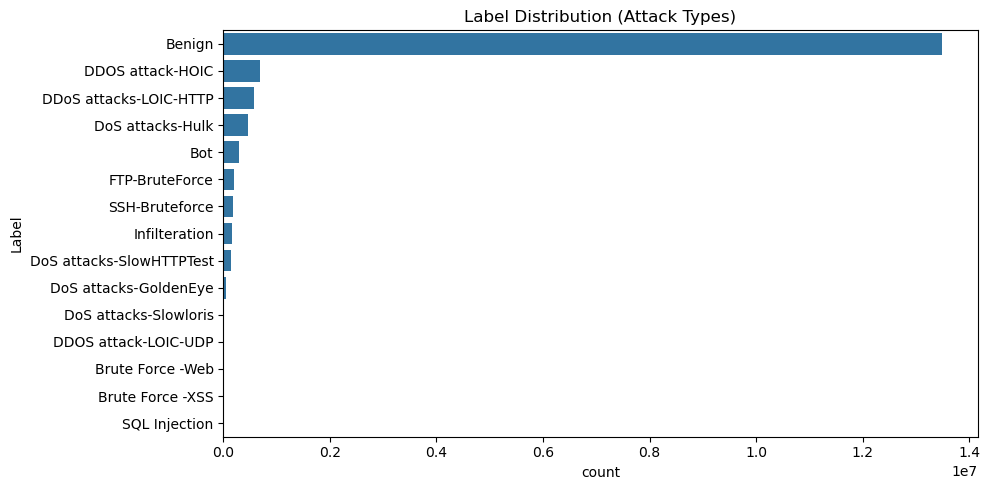

In [4]:
#Label distribution in each file 

for fname, df in cleaned_dfs.items():
    print(f"\n{fname}")
    if 'Label' in df.columns:
        print(df['Label'].value_counts())
    else:
        print("No 'Label' column found.")

#Label distribution in the combined dataset 
if cleaned_dfs:
    combined = pd.concat(cleaned_dfs.values(), ignore_index=True)
    print(f"\nCombined dataset shape: {combined.shape}")

    # Save to CSV
    combined.to_csv('combined.csv', index=False)
    print("Saved combined dataset as 'combined.csv'")
    
    # Full label distribution
    counts = combined['Label'].value_counts()
    percentages = (counts / len(combined)) * 100
    label_dist = pd.DataFrame({'Count': counts, 'Percentage': percentages})
    print("\nFull dataset label distribution:")
    print(label_dist)
else:
    print("No valid data to analyze")
    
# Visualization
plt.figure(figsize=(10, 5))
sns.countplot(data=combined, y='Label', order=counts.index)
plt.title("Label Distribution (Attack Types)")
plt.tight_layout()
plt.show()

## Basic Data Checks

In [6]:
print(f"Total Rows: {len(combined)}")
print(f"Total Columns: {len(combined.columns)}")
print("\nFirst 5 Rows:")
print(combined.head())
print("\nData Types:")
print(combined.dtypes.value_counts())




Total Rows: 16232943
Total Columns: 80

First 5 Rows:
  Dst Port Protocol            Timestamp Flow Duration Tot Fwd Pkts  \
0      443        6  02/03/2018 08:47:38        141385            9   
1    49684        6  02/03/2018 08:47:38           281            2   
2      443        6  02/03/2018 08:47:40        279824           11   
3      443        6  02/03/2018 08:47:40           132            2   
4      443        6  02/03/2018 08:47:41        274016            9   

  Tot Bwd Pkts TotLen Fwd Pkts TotLen Bwd Pkts Fwd Pkt Len Max  \
0            7             553          3773.0             202   
1            1              38             0.0              38   
2           15            1086         10527.0             385   
3            0               0             0.0               0   
4           13            1285          6141.0             517   

  Fwd Pkt Len Min  ... Fwd Seg Size Min Active Mean Active Std Active Max  \
0               0  ...               20      